# Giải thích quy trình tiền xử lý dữ liệu PAPI (6 bước chuẩn Day 4)

**Học máy · Nhóm 15**  
Nguyễn Tiến Sơn (24110054), Trần Thị Ngọc Quyên (24110051)

Mỗi dòng là một tỉnh trong một năm (`63 tỉnh × 14 năm = 882 quan sát`). Notebook này giải thích vì sao từng quyết định tiền xử lý trong `notebooks/Nhom15_TienXuLy_PAPI.ipynb` và `src/preprocessing.py` được đặt đúng thứ tự theo bài giảng Tiền xử lý dữ liệu (**Define algorithm first → Cleaning → Integration → Feature Selection & Transformation → Pipeline**). Mở notebook trong thư mục `study/` của dự án và chọn **Restart Kernel and Run All Cells**.

## 1. Xác định bài toán & Nạp 14 workbook PAPI gốc

- **Thuật toán đích là STING (`n_levels=3, factor=4, min_count=5`)** — một thuật toán phân cụm dựa trên lưới chữ nhật đều theo từng chiều. Vì vậy dữ liệu đầu vào phải sạch khóa tỉnh–năm, thang đo tương đương xuyên năm, và không được mất các điểm cực trị hợp lệ làm co biên lưới.
- Hai hàm `parse_old` (2011–2019: tỉnh theo hàng) và `parse_new` (2020–2024: ma trận chuyển vị) trong `src/preprocessing.py` chuẩn hóa tên cột chỉ tiêu về định dạng chung trước khi ghép.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle

cwd = Path.cwd().resolve()
root = next(
    (
        cand
        for parent in (cwd, *cwd.parents)
        for cand in (parent / "tai_lieu_kem", parent)
        if (cand / "src" / "preprocessing.py").is_file()
        and (cand / "data" / "raw" / "papi").is_dir()
    ),
    None,
)
if root is None:
    raise FileNotFoundError(
        "Hãy mở notebook từ thư mục dự án, thư mục 03-tien-xu-ly-papi hoặc gói đã giải nén cùng tai_lieu_kem."
    )

sys.path.insert(0, str(root / "src"))
sys.path.insert(0, str(root))

from preprocessing import (
    ALLOWLIST_FEATURES,
    DEFAULT_CUTOFF_YEAR,
    FEATURE_LABELS,
    NEW_FILES,
    OLD_FILES,
    PREPROCESSING_PIPELINE,
    analyze_missingness,
    check_external_integration,
    count_range_violations,
    feature_selection_summary,
    load_crosswalk,
    load_raw_papi,
    run_preprocessing_pipeline,
    run_sting_preprocessing_experiments,
    scale_audit,
    score_columns,
    step_check_consistency,
    step_clean_codes_and_zeros,
    step_deduplicate,
    step_flag_outliers,
    step_integrate_panel,
    step_select_and_scale,
)
from scripts.common.fig_style import CLUSTER_COLORS, PALETTE, apply_style, style_context

apply_style()

cfg = json.loads((root / "models" / "predict_config.json").read_text(encoding="utf-8"))
features = list(cfg["features"])
raw, diagnostics = load_raw_papi(root / "data" / "raw" / "papi")
print("Đã nạp src/preprocessing.py và cấu hình tiền xử lý PAPI.")
print(f"Đã đọc {len(OLD_FILES) + len(NEW_FILES)} workbook: {len(raw)} dòng × {raw.shape[1]} cột thô.")
display(diagnostics.set_index("year").T)

Đã nạp src/preprocessing.py và cấu hình tiền xử lý PAPI.
Đã đọc 14 workbook: 882 dòng × 40 cột thô.


year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
format,2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2011–2019 (tỉnh là hàng),2020–2024 (chuyển vị),2020–2024 (chuyển vị),2020–2024 (chuyển vị),2020–2024 (chuyển vị),2020–2024 (chuyển vị)
provinces,63,63,63,63,63,63,63,63,63,63,63,63,63,63
dims,6,6,6,6,6,6,6,8,8,8,8,8,8,8
subs,22,22,22,22,22,22,22,28,29,29,28,28,28,28


## 2. Giai đoạn 1 — Làm sạch (Cleaning đúng thứ tự)

Vì sao phải làm sạch đúng thứ tự **Deduplicate → Missing/0.0→NaN → Consistency & Scale Audit → Outliers**?
1. **Khử trùng lặp đầu tiên**: nếu trùng dòng chưa bỏ mà đi tính `mean/std` hay `NaN` thì mọi thống kê bước sau đều lệch (khử cả trùng toàn dòng và trùng khóa `(province_code, year)` sau quy đổi crosswalk).
2. **Xử lý thiếu & `0.0 → NaN`**: trong bộ Mendeley/PAPI, `0.0` biểu thị tỉnh chưa được xếp hạng chứ không phải điểm `0`; tách bạch thiếu cấu trúc (`d7/d8` trước 2018, các tiểu chiều mới) và thiếu trong giai đoạn (`13` dòng thiếu `sd_4_2` hoặc `sd_6_1`). Không điền `median` vì sẽ dồn điểm giả về ô trung tâm.
3. **Tính nhất quán & `scale_audit`**: kiểm tra `0` lệch mã crosswalk, `0` ô vượt khoảng metadata, và dùng bước nhảy `|Δmean| > 0.25` sàng lọc `23/37` cột nghi biến động thang đo.
4. **Đánh dấu ngoại lai cuối cùng**: chỉ dùng `|z| > 3` để gán cờ nhận diện điểm cực trị (cả 37 cột và 2 biến STING), **không xóa** vì đây là điểm thật hợp lệ của các địa phương.

In [2]:
crosswalk_path = (
    root / "data" / "raw" / "mendeley" / "Replication_package" / "data" / "province_crosswalk_63.csv"
)
metadata_path = root / "data" / "processed" / "papi_panel_scale_metadata.csv"
metadata = pd.read_csv(metadata_path)
crosswalk = pd.read_csv(crosswalk_path)
crosswalk_codes = crosswalk["province_code"].astype(int).unique()
s_cols = score_columns(raw)

ctx = {
    "root": root,
    "raw": raw,
    "crosswalk_maps": load_crosswalk(crosswalk_path),
    "crosswalk_codes": crosswalk_codes,
    "metadata": metadata,
    "score_cols": s_cols,
    "features": features,
    "cutoff_year": DEFAULT_CUTOFF_YEAR,
    "z_threshold": 3.0,
    "log": [],
}

ctx = step_deduplicate(ctx)
dedup = ctx["dedup_stats"]
print(f"[2a. Trùng lặp] Trùng toàn dòng: {dedup['exact_duplicates']} | "
      f"Trùng khóa (province_code, year): {dedup['key_duplicates']}/{dedup['rows']} dòng.")

ctx = step_clean_codes_and_zeros(ctx)
miss = ctx["missing_summary"]
print(f"[2b. Giá trị thiếu] {miss['total_zeros']} ô 0.0 → NaN | "
      f"Tổng {miss['total_missing']}/{miss['total_cells']} ô thiếu: "
      f"{miss['structural_missing']} ô ngoài giai đoạn khảo sát + "
      f"{miss['in_window_missing']} ô trong giai đoạn khảo sát trên {miss['in_window_rows']} dòng.")
display(miss["per_column"].loc[[*features, "Toàn bộ 37 cột chỉ tiêu"]])

ctx = step_check_consistency(ctx)
cons = ctx["consistency_stats"]
jump_flags = ctx["scale_flags"]
flagged_names = ctx["flagged_names"]
print(f"[2c. Nhất quán & thang đo] Lệch mã tỉnh crosswalk: {cons['code_mismatch']} | "
      f"Ô ngoài khoảng metadata: {cons['range_violations']} | "
      f"Cờ biến động TB năm > 0.25: {cons['scale_flagged_count']}/37 cột.")
print("  8 đặc trưng allowlist bị cờ:", [c for c in ALLOWLIST_FEATURES if c in flagged_names])
display(pd.DataFrame(jump_flags, columns=["Chỉ tiêu", "Bước nhảy |Δmean| lớn nhất", "Tại năm"]).head(8))

ctx = step_flag_outliers(ctx)
out_st = ctx["outlier_stats"]
print(f"[2d. Ngoại lai (cuối cùng)] Toàn panel 37 chỉ tiêu: {out_st['panel_cells']} ô |z| > 3 "
      f"trên {out_st['panel_rows']} dòng / {out_st['panel_cols']} cột → GIỮ (chỉ đánh dấu, không xóa).")

[2a. Trùng lặp] Trùng toàn dòng: 0 | Trùng khóa (province_code, year): 0/882 dòng.


[2b. Giá trị thiếu] 109 ô 0.0 → NaN | Tổng 4649/32634 ô thiếu: 4284 ô ngoài giai đoạn khảo sát + 365 ô trong giai đoạn khảo sát trên 13 dòng.


,Ô bằng 0 trước xử lý,Ô thiếu trước xử lý,Ô thiếu sau xử lý,Tỷ lệ thiếu (%)
sd_4_2,4,9,13,1.47
sd_6_1,2,7,9,1.02
Toàn bộ 37 cột chỉ tiêu,109,4540,4649,14.25


[2c. Nhất quán & thang đo] Lệch mã tỉnh crosswalk: 0 | Ô ngoài khoảng metadata: 0 | Cờ biến động TB năm > 0.25: 23/37 cột.
  8 đặc trưng allowlist bị cờ: []


,Chỉ tiêu,Bước nhảy |Δmean| lớn nhất,Tại năm
0,sd_2_1,1.355,2018
1,d7,0.988,2019
2,sd_7_1,0.970,2019
3,sd_8_3,0.847,2020
4,d6,0.715,2021
5,d3,0.676,2016
6,sd_8_2,0.672,2019
7,sd_3_3,0.650,2016


[2d. Ngoại lai (cuối cùng)] Toàn panel 37 chỉ tiêu: 122 ô |z| > 3 trên 98 dòng / 29 cột → GIỮ (chỉ đánh dấu, không xóa).


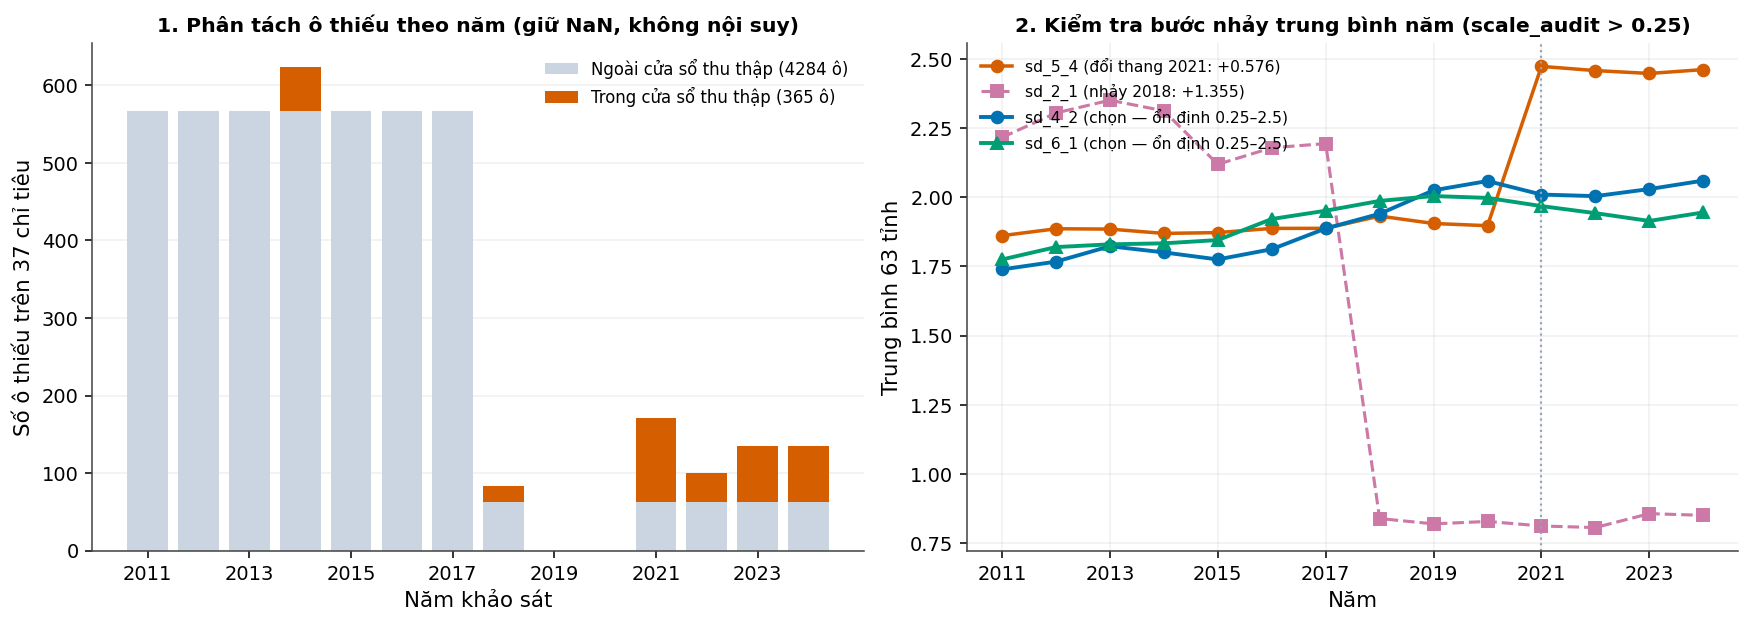

In [3]:
by_year = miss["by_year"]
clean_df = ctx["clean"]
yearly_means = clean_df.groupby("year")[["sd_5_4", "sd_2_1", "sd_4_2", "sd_6_1"]].mean()

with style_context():
    fig, (ax_m, ax_s) = plt.subplots(1, 2, figsize=(12.4, 4.35), dpi=140, layout="constrained")

    yrs = by_year["Năm"].to_numpy()
    s_miss = by_year["Thiếu cấu trúc (ngoài cửa sổ)"].to_numpy()
    w_miss = by_year["Thiếu trong cửa sổ"].to_numpy()
    ax_m.bar(yrs, s_miss, color="#CBD5E1", label=f"Ngoài cửa sổ thu thập ({int(s_miss.sum())} ô)")
    ax_m.bar(yrs, w_miss, bottom=s_miss, color="#D55E00", label=f"Trong cửa sổ thu thập ({int(w_miss.sum())} ô)")
    ax_m.set_title("1. Phân tách ô thiếu theo năm (giữ NaN, không nội suy)", fontsize=10.5)
    ax_m.set_xlabel("Năm khảo sát")
    ax_m.set_ylabel("Số ô thiếu trên 37 chỉ tiêu")
    ax_m.set_xticks(yrs[::2])
    ax_m.grid(axis="y", alpha=0.18)
    ax_m.legend(loc="upper right", fontsize=8.5, framealpha=0.92)

    ax_s.plot(yearly_means.index, yearly_means["sd_5_4"], "o-", color="#D55E00", lw=1.8,
              label="sd_5_4 (đổi thang 2021: +0.576)")
    ax_s.plot(yearly_means.index, yearly_means["sd_2_1"], "s--", color=PALETTE["purple"], lw=1.6,
              label="sd_2_1 (nhảy 2018: +1.355)")
    ax_s.plot(yearly_means.index, yearly_means["sd_4_2"], "o-", color=PALETTE["blue"], lw=2.0,
              label="sd_4_2 (chọn — ổn định 0.25–2.5)")
    ax_s.plot(yearly_means.index, yearly_means["sd_6_1"], "^-", color=PALETTE["green"], lw=2.0,
              label="sd_6_1 (chọn — ổn định 0.25–2.5)")
    ax_s.axvline(2021, color="#94A3B8", linestyle=":", lw=1.1)
    ax_s.set_title("2. Kiểm tra bước nhảy trung bình năm (scale_audit > 0.25)", fontsize=10.5)
    ax_s.set_xlabel("Năm")
    ax_s.set_ylabel("Trung bình 63 tỉnh")
    ax_s.set_xticks(yrs[::2])
    ax_s.grid(alpha=0.18)
    ax_s.legend(loc="upper left", fontsize=8.0, framealpha=0.92)
    plt.show()

## 3. Giai đoạn 2 — Tích hợp & Chống rò rỉ dữ liệu (Integration)

- Ghép `many_to_one` với bảng tên tỉnh chuẩn (`validate='many_to_one'`) để chặn lỗi nhân bản dòng.
- Đối chiếu khớp số học `1e-12` với `data/processed/papi_panel_63_2011_2024.csv` (`882 × 41`, `39` cột số ≥ chuẩn `500 × 10`).
- **Ranh giới thời gian chống rò rỉ (Anti-leakage)**: tách `2011–2023` làm tập huấn luyện (`808` dòng đủ 2 biến) và giữ `2024` (`61` dòng đủ 2 biến) hoàn toàn tách biệt trước khi ước lượng mọi tham số biến đổi.

In [4]:
reference = pd.read_csv(root / "data" / "processed" / "papi_panel_63_2011_2024.csv")
ctx["column_order"] = list(reference.columns)
ctx = step_integrate_panel(ctx)
panel = ctx["panel"]

reference_sorted = reference.sort_values(["province_code", "year"]).reset_index(drop=True)
pd.testing.assert_frame_equal(panel, reference_sorted, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)

n_rows, n_cols = panel.shape
n_num = panel.select_dtypes("number").shape[1]
assert n_rows >= 500 and n_num >= 10
print(f"Panel tích hợp khớp CSV công bố: {n_rows} dòng × {n_cols} cột ({n_num} cột số), {panel['province_code'].nunique()} tỉnh.")

ctx = step_select_and_scale(ctx)
train_df = ctx["train_df"]
holdout_df = ctx["holdout_df"]
print(f"Tách chống rò rỉ: {len(panel) - len(ctx['complete_df'])} dòng thiếu cặp {features} → "
      f"Train (2011–2023): {len(train_df)} dòng | Holdout (2024): {len(holdout_df)} dòng.")

master_path = root / "data" / "processed" / "external_master_63_2011_2024.csv"
if master_path.is_file():
    ext_info = check_external_integration(panel, master_path)
    print(f"Đối chiếu bảng ngoại lai external_master: {ext_info['shape']}, quan hệ {ext_info['cardinality']}, "
          f"khớp khóa={ext_info['same_keys']}, lệch max={ext_info['max_shared_diff']:.2e}.")
    display(ext_info["masks"])
else:
    print("Môi trường chạy PAPI độc lập (không kèm bảng ngoại lai cuối kỳ) — chỉ kiểm chứng panel 882×41.")
display(panel[["province_code", "year", "province_vi", *features]].head())

Panel tích hợp khớp CSV công bố: 882 dòng × 41 cột (39 cột số), 63 tỉnh.
Tách chống rò rỉ: 13 dòng thiếu cặp ['sd_4_2', 'sd_6_1'] → Train (2011–2023): 808 dòng | Holdout (2024): 61 dòng.
Đối chiếu bảng ngoại lai external_master: (882, 59), quan hệ one_to_one, khớp khóa=True, lệch max=1.33e-15.


,Cột mask,Ô có dữ liệu,Tổng dòng,Độ phủ (%)
0,pci_present,816,882,92.5
1,pop_present,882,882,100.0
2,grdp_present,441,882,50.0
3,odm_present,63,882,7.1
4,waste_present,305,882,34.6
5,papi_sd46_present,869,882,98.5


,province_code,year,province_vi,sd_4_2,sd_6_1
0,1,2011,Hà Nội,1.585172,1.746413
1,1,2012,Hà Nội,1.499400,1.676689
2,1,2013,Hà Nội,1.630049,1.592731
3,1,2014,Hà Nội,1.564298,1.512394
4,1,2015,Hà Nội,1.533680,1.597215


## 4. Giai đoạn 3 — Chọn đặc trưng, Chuẩn hóa & Thử nghiệm tiền xử lý

### 4.1 Giải thích bước sàng lọc đặc trưng & StandardScaler
- Loại `d1–d8` (chỉ số tổng hợp thang `1–10`) và loại các tiểu chiều bị cờ `scale_audit` hoặc thiếu cấu trúc, giữ **8 chỉ tiêu sạch** trong `ALLOWLIST_FEATURES`.
- Kiểm tra phương sai `> 0.01` (không biến gần hằng số) và tương quan cặp Pearson trên `2011–2023` (không đa cộng tuyến; cặp chọn `sd_4_2, sd_6_1` có `r = 0.5006`), sau đó fit `StandardScaler` (`ddof=0`) **chỉ trên `2011–2023`** rồi transform sang `2024`.

In [5]:
fs_summary, corr_8 = feature_selection_summary(
    panel, s_cols, candidate_features=ALLOWLIST_FEATURES, cutoff_year=DEFAULT_CUTOFF_YEAR, flagged_names=flagged_names
)
variances = fs_summary["Phương sai (ddof=0)"]
assert (variances > 0.01).all(), "Phát hiện đặc trưng gần hằng số."
corr_42_61 = float(corr_8.loc["sd_4_2", "sd_6_1"])
print(f"Loại {len(s_cols) - len(ALLOWLIST_FEATURES)}/37 cột điểm → giữ {len(ALLOWLIST_FEATURES)} chỉ tiêu sạch (2011–2023):")
print(f"  min var = {variances.min():.4f} > 0.01 | max |r| cặp bất kỳ = {fs_summary['|r| max với biến khác'].max():.4f} | "
      f"Pearson r(sd_4_2, sd_6_1) = {corr_42_61:.4f}.")
display(fs_summary.round(4))

scaler = ctx["scaler"]
train_scaled = pd.DataFrame(ctx["X_train"], columns=features, index=train_df.index)
holdout_scaled = pd.DataFrame(ctx["X_holdout"], columns=features, index=holdout_df.index)
np.testing.assert_allclose(train_scaled.mean(), 0.0, atol=1e-12)
np.testing.assert_allclose(train_scaled.std(ddof=0), 1.0, atol=1e-12)

scaler_json_path = root / "models" / "sting_predict_scaler.json"
if scaler_json_path.is_file():
    saved_sc = json.loads(scaler_json_path.read_text(encoding="utf-8"))
    np.testing.assert_allclose(scaler.mean_, saved_sc["mean"], rtol=0, atol=1e-12)
    np.testing.assert_allclose(scaler.scale_, saved_sc["scale"], rtol=0, atol=1e-12)
    print("Tham số StandardScaler khớp models/sting_predict_scaler.json với dung sai tuyệt đối 1e-12.")

extreme = train_scaled.abs().gt(3.0).any(axis=1)
assert int(extreme.sum()) == int(ctx["train_outlier_mask"].sum())
holdout_max_z = float(holdout_scaled.abs().to_numpy().max())
print(f"Ngoại lai |z| > 3 trên hai chỉ tiêu (2011–2023): {int(extreme.sum())}/{len(train_df)} dòng | "
      f"2024: {int(holdout_scaled.abs().gt(3).any(axis=1).sum())}/{len(holdout_df)} dòng (max |z| = {holdout_max_z:.4f}).")
display(
    panel.loc[train_df.index[extreme], ["province_vi", "year", *features]]
    .join(train_scaled.loc[extreme].rename(columns={"sd_4_2": "sd_4_2_z", "sd_6_1": "sd_6_1_z"}))
    .round(4)
    .reset_index(drop=True)
)

Loại 29/37 cột điểm → giữ 8 chỉ tiêu sạch (2011–2023):
  min var = 0.0193 > 0.01 | max |r| cặp bất kỳ = 0.8412 | Pearson r(sd_4_2, sd_6_1) = 0.5006.


,Tên chỉ tiêu,Min (≤cutoff),Max (≤cutoff),Phương sai (ddof=0),|r| max với biến khác,Bị cờ scale_audit,Loại khỏi 37 cột
sd_1_3,1.3 Chất lượng bầu cử,1.0186,1.8971,0.0255,0.2408,False,29
sd_1_4,1.4 Đóng góp tự nguyện,0.4248,1.7958,0.0544,0.4400,False,29
sd_4_1,4.1 Kiểm soát tham nhũng trong chính quyền địa...,0.7040,2.1993,0.0525,0.8412,False,29
sd_4_2,4.2 Kiểm soát tham nhũng trong cung ứng dịch v...,1.1753,2.3557,0.0332,0.8412,False,29
sd_4_3,4.3 Công bằng trong tuyển dụng vào khu vực công,0.4630,1.7242,0.0485,0.8151,False,29
sd_4_4,4.4 Quyết tâm chống tham nhũng của chính quyền...,0.9754,2.1496,0.0268,0.5036,False,29
sd_6_1,6.1 Y tế công lập,1.4348,2.2153,0.0193,0.5089,False,29
sd_6_3,6.3 Cơ sở hạ tầng căn bản,1.1978,2.4639,0.0676,0.4453,False,29


Tham số StandardScaler khớp models/sting_predict_scaler.json với dung sai tuyệt đối 1e-12.
Ngoại lai |z| > 3 trên hai chỉ tiêu (2011–2023): 7/808 dòng | 2024: 0/61 dòng (max |z| = 2.1299).


,province_vi,year,sd_4_2,sd_6_1,sd_4_2_z,sd_6_1_z
0,Điện Biên,2012,1.2634,1.8992,-3.4756,-0.0462
1,Hải Phòng,2011,1.2995,1.6023,-3.2774,-2.1835
2,Hải Phòng,2015,1.6610,1.4378,-1.2944,-3.3672
3,Hải Phòng,2017,1.1753,1.7633,-3.9589,-1.0246
4,Lâm Đồng,2011,1.5818,1.4688,-1.7290,-3.1447
5,Bình Dương,2015,1.5523,1.4348,-1.8905,-3.3888
6,Bình Dương,2016,1.3249,1.6404,-3.1382,-1.9093


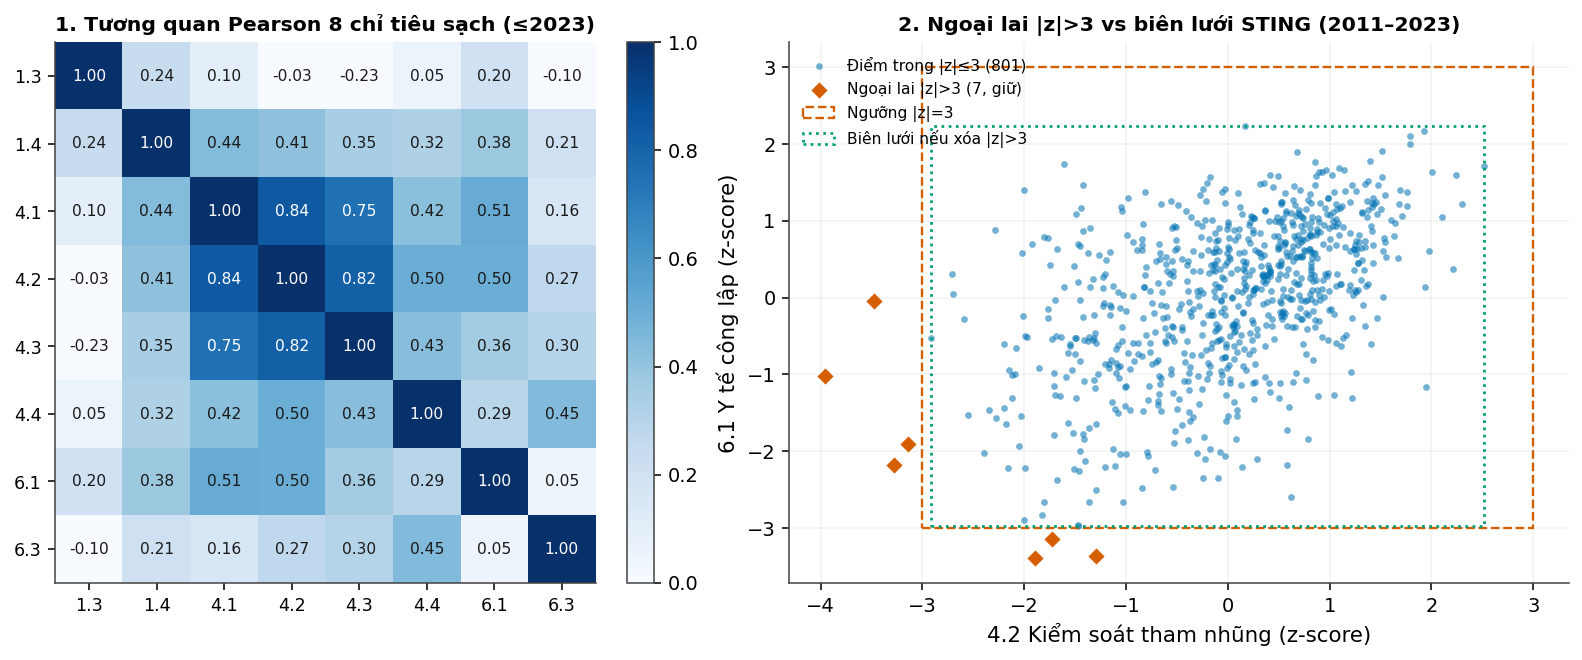

In [6]:
with style_context():
    fig, (ax_h, ax_o) = plt.subplots(1, 2, figsize=(12.6, 4.6), dpi=140, layout="constrained")

    im = ax_h.imshow(corr_8.to_numpy(), cmap="Blues", vmin=0.0, vmax=1.0)
    short_names = [c.removeprefix("sd_").replace("_", ".") for c in corr_8.columns]
    ax_h.set_xticks(range(len(short_names)), short_names, fontsize=9)
    ax_h.set_yticks(range(len(short_names)), short_names, fontsize=9)
    for i in range(len(short_names)):
        for j in range(len(short_names)):
            val = corr_8.iloc[i, j]
            ax_h.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
                      color="white" if val > 0.6 else "#1A1A1A")
    fig.colorbar(im, ax=ax_h, fraction=0.046, pad=0.04)
    ax_h.set_title("1. Tương quan Pearson 8 chỉ tiêu sạch (≤2023)", fontsize=10.5)

    X_z_tr = train_scaled.to_numpy()
    ex_arr = extreme.to_numpy()
    ax_o.scatter(X_z_tr[~ex_arr, 0], X_z_tr[~ex_arr, 1], s=12, color=PALETTE["blue"], alpha=0.55,
                 linewidths=0, label=f"Điểm trong |z|≤3 ({int((~ex_arr).sum())})")
    ax_o.scatter(X_z_tr[ex_arr, 0], X_z_tr[ex_arr, 1], s=42, color="#D55E00", marker="D",
                 edgecolors="white", linewidths=0.6, label=f"Ngoại lai |z|>3 ({int(ex_arr.sum())}, giữ)", zorder=4)
    ax_o.add_patch(Rectangle((-3.0, -3.0), 6.0, 6.0, fill=False, edgecolor="#D55E00",
                             linestyle="--", linewidth=1.2, label="Ngưỡng |z|=3"))
    kept = X_z_tr[~ex_arr]
    ax_o.add_patch(Rectangle(
        (kept[:, 0].min(), kept[:, 1].min()),
        kept[:, 0].max() - kept[:, 0].min(),
        kept[:, 1].max() - kept[:, 1].min(),
        fill=False, edgecolor=PALETTE["green"], linestyle=":", linewidth=1.4, label="Biên lưới nếu xóa |z|>3",
    ))
    ax_o.set_title("2. Ngoại lai |z|>3 vs biên lưới STING (2011–2023)", fontsize=10.5)
    ax_o.set_xlabel("4.2 Kiểm soát tham nhũng (z-score)")
    ax_o.set_ylabel("6.1 Y tế công lập (z-score)")
    ax_o.grid(alpha=0.16)
    ax_o.legend(loc="upper left", fontsize=8.0, framealpha=0.92)
    plt.show()

### 4.2 Giải thích định lượng các thí nghiệm Cleaning & Transformation
- Lưới STING mức 2 (`16 × 16` ô đều) bản chất là **rời rạc hóa theo độ rộng bằng nhau (Equal-Width Discretization)**.
- Do đó biến đổi tuyến tính (`StandardScaler`, `MinMaxScaler`) giữ nguyên `808/808` ô cho mọi điểm, còn biến đổi phi tuyến (`QuantileTransformer`) bẻ cong khoảng cách và làm thay đổi mật độ ô/số cụm.
- Tương tự ở Cleaning: xóa `7` điểm `|z| > 3` làm co biên `[min, max]` của lưới nên tỷ lệ nhiễu STING tăng (`19.6% → 24.6%`); còn `SimpleImputer(median)` đẩy `11` dòng thiếu về trung vị `sd_4_2` (`158 → 160` nhiễu).

In [7]:
exp_df, exp_arts = run_sting_preprocessing_experiments(
    panel, sting_cfg=cfg["sting"], features=features, cutoff_year=DEFAULT_CUTOFF_YEAR
)
display(exp_df)

sens_path = root / "results" / "preprocessing_sensitivity.csv"
if sens_path.is_file():
    print("Đối chiếu độ nhạy mở rộng trên học có giám sát (results/preprocessing_sensitivity.csv):")
    display(pd.read_csv(sens_path)[["task", "model", "variant", "n_train_pairs", "value_cv", "delta_vs_A", "verdict"]])

,Số dòng,Số cụm,Số ô dày,Điểm nhiễu (−1),Tỷ lệ nhiễu,Giữ nguyên ô vs z-score
1. Pipeline chọn (dropna + giữ |z|>3 + StandardScaler),808,3,56,158,19.6%,808/808 (chuẩn)
2. Cleaning: Xóa 7 điểm |z|>3 (co biên lưới),801,4,59,197,24.6%,n/a (đổi mẫu)
3. Cleaning: Điền SimpleImputer(median) cho 11 dòng thiếu,819,3,56,160,19.5%,n/a (đổi mẫu)
4. Transform: Điểm gốc (không scale),808,3,56,158,19.6%,808/808
"5. Transform: MinMaxScaler [0, 1] (affine)",808,3,56,158,19.6%,808/808
6. Transform: QuantileTransformer (phi tuyến),808,24,62,403,49.9%,9/808


Đối chiếu độ nhạy mở rộng trên học có giám sát (results/preprocessing_sensitivity.csv):


,task,model,variant,n_train_pairs,value_cv,delta_vs_A,verdict
0,regression,ridge,A,740,0.265,0.000,—
1,regression,ridge,B,749,0.250,-0.015,không khác biệt
2,regression,ridge,C,740,0.264,-0.001,không khác biệt
3,classification,logistic regression,A,738,0.434,0.000,—
4,classification,logistic regression,B,745,0.434,0.000,không khác biệt
5,classification,logistic regression,C,738,0.420,-0.014,không khác biệt
6,classification,gaussian naive bayes,A,738,0.514,0.000,—
7,classification,gaussian naive bayes,B,745,0.512,-0.002,không khác biệt
8,classification,gaussian naive bayes,C,738,0.513,-0.001,không khác biệt


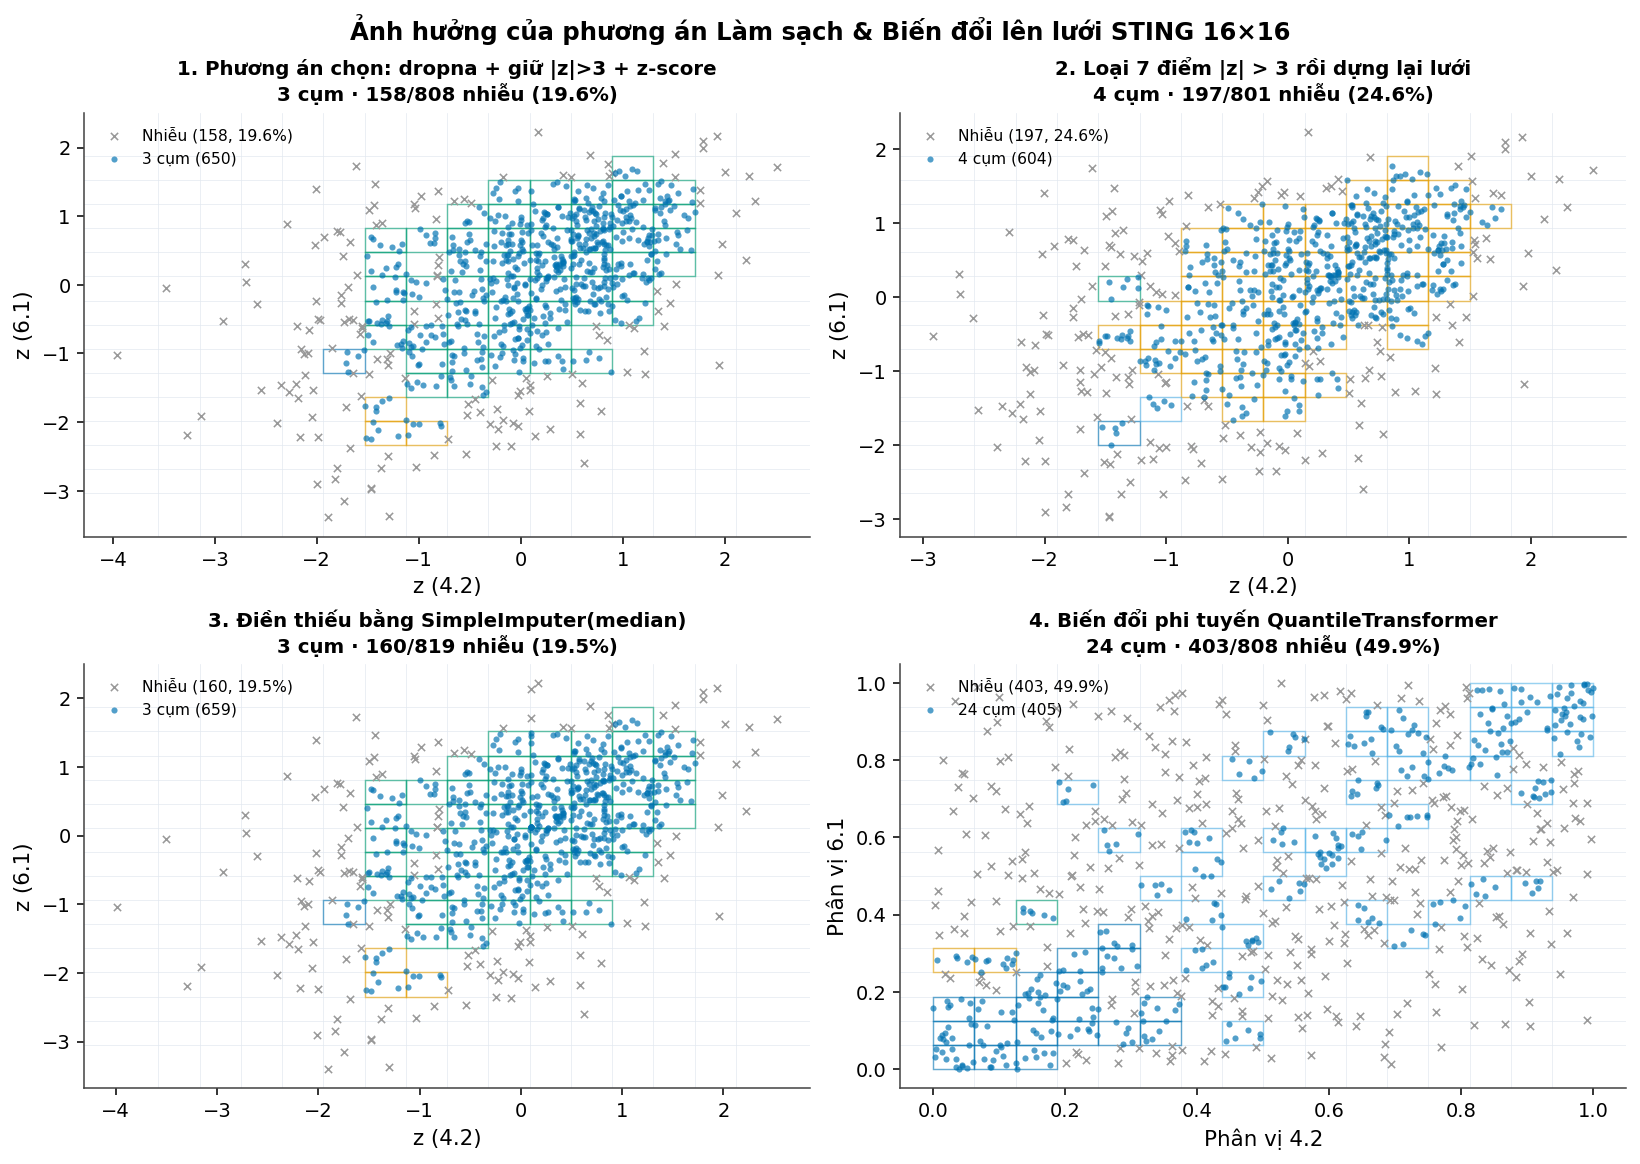

In [8]:
panels = [
    ("standard", "1. Phương án chọn: dropna + giữ |z|>3 + z-score", "z (4.2)", "z (6.1)"),
    ("trimmed", "2. Loại 7 điểm |z| > 3 rồi dựng lại lưới", "z (4.2)", "z (6.1)"),
    ("imputed", "3. Điền thiếu bằng SimpleImputer(median)", "z (4.2)", "z (6.1)"),
    ("quantile", "4. Biến đổi phi tuyến QuantileTransformer", "Phân vị 4.2", "Phân vị 6.1"),
]

with style_context():
    fig, axes = plt.subplots(2, 2, figsize=(11.6, 8.2), dpi=140, layout="constrained")
    for ax, (key, title, xlab, ylab) in zip(axes.ravel(), panels, strict=True):
        art = exp_arts[key]
        X_arr, m, lab = art["X"], art["model"], art["labels"]
        res = m.factor ** m.cluster_level_
        lo_g, hi_g = m.bounds_min_, m.bounds_max_
        step_g = (hi_g - lo_g) / res
        for idx_c, cid in m.label_of_.items():
            cell = m.cells_[m.cluster_level_][idx_c]
            ax.add_patch(Rectangle(
                cell.bounds_min, *(cell.bounds_max - cell.bounds_min),
                facecolor="none", edgecolor=CLUSTER_COLORS.get(cid, PALETTE["sky"]), linewidth=0.75, alpha=0.6,
            ))
        for i in range(1, res):
            ax.axvline(lo_g[0] + i * step_g[0], color="#E2E8F0", linewidth=0.35, zorder=0.5)
            ax.axhline(lo_g[1] + i * step_g[1], color="#E2E8F0", linewidth=0.35, zorder=0.5)
        ns = lab == -1
        ax.scatter(X_arr[ns, 0], X_arr[ns, 1], s=14, color=PALETTE["gray"], marker="x",
                   linewidths=0.8, label=f"Nhiễu ({int(ns.sum())}, {ns.mean():.1%})", zorder=2)
        ax.scatter(X_arr[~ns, 0], X_arr[~ns, 1], s=10, color=PALETTE["blue"], alpha=0.68,
                   linewidths=0, label=f"{m.n_clusters_} cụm ({int((~ns).sum())})", zorder=2)
        ax.set_title(f"{title}\n{m.n_clusters_} cụm · {int(ns.sum())}/{len(lab)} nhiễu ({ns.mean():.1%})", fontsize=10.2)
        ax.set_xlabel(xlab)
        ax.set_ylabel(ylab)
        ax.legend(loc="upper left", fontsize=8.0, framealpha=0.92)
    fig.suptitle("Ảnh hưởng của phương án Làm sạch & Biến đổi lên lưới STING 16×16", fontsize=12.5)
    plt.show()

## 5. Đóng gói Pipeline (`List of functions`) & Đối chiếu tái lập

Thực thi trọn vẹn danh sách hàm tuần tự `PREPROCESSING_PIPELINE` trong `src/preprocessing.py` và kiểm tra khớp `atol=1e-12` với phân tích từng bước ở trên.

In [9]:
print("Các bước trong src/preprocessing.py::PREPROCESSING_PIPELINE:")
for idx, (step_name, fn) in enumerate(PREPROCESSING_PIPELINE, start=1):
    print(f"  {idx}. {step_name} -> {fn.__name__}()")

state = run_preprocessing_pipeline(root, features=features, cutoff_year=DEFAULT_CUTOFF_YEAR)

assert int(state["panel_outlier_mask"].sum().sum()) == int(ctx["panel_outlier_mask"].sum().sum())
assert int(state["train_outlier_mask"].sum()) == int(extreme.sum())
np.testing.assert_allclose(state["X_train"], train_scaled.to_numpy(), rtol=0, atol=1e-12)
np.testing.assert_allclose(state["X_holdout"], holdout_scaled.to_numpy(), rtol=0, atol=1e-12)
pd.testing.assert_frame_equal(state["panel"], reference_sorted, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)

print("Pipeline tái lập kết quả từng bước và các giá trị trong CSV trong dung sai 1e-12.")
display(pd.DataFrame(state["log"], columns=["Bước trong pipeline", "Kết quả thực thi"]))

Các bước trong src/preprocessing.py::PREPROCESSING_PIPELINE:
  1. Deduplication -> step_deduplicate()
  2. Missing & Zero Convention -> step_clean_codes_and_zeros()
  3. Consistency & Scale Audit -> step_check_consistency()
  4. Outlier Flagging -> step_flag_outliers()
  5. Integration & Ordering -> step_integrate_panel()
  6. Feature Selection & Scaling -> step_select_and_scale()


Pipeline tái lập kết quả từng bước và các giá trị trong CSV trong dung sai 1e-12.


,Bước trong pipeline,Kết quả thực thi
0,1. Cleaning — Deduplicate (đầu tiên),882 dòng (trùng toàn dòng: 0; trùng khóa tỉnh–...
1,2. Cleaning — Missing & 0.0→NaN,109 ô 0.0 → NaN; tổng 4649 ô NaN (4284 ngoài c...
2,3. Cleaning — Consistency & Scale Audit,0 xung đột mã; 0 vi phạm miền; 23/37 cột bị cờ...
3,4. Cleaning — Flag outliers (cuối Cleaning),toàn panel: 122 ô/98 dòng/29 cột; train 2 biến...
4,5. Integration — Merge & Sort,"882 dòng × 41 cột, 63 tỉnh, 0 xung đột khóa"
5,6. Transformation — StandardScaler (≤2023),"train=(808, 2), holdout=(61, 2) (fit chỉ trên ..."


## Kết luận (Tóm tắt quyết định tiền xử lý)

1. Hợp nhất 14 workbook (`2011–2019` và `2020–2024`) → `882` dòng thô.
2. Deduplicate toàn dòng (`0`) và khóa `(province_code, year)` (`0`) ở **đầu Cleaning**.
3. Quy `109` ô `0.0 → NaN`, tách thiếu cấu trúc vs trong giai đoạn, **giữ `NaN` và chỉ `dropna` theo mẫu bài toán**.
4. Kiểm chứng `0` lỗi crosswalk, `0` lỗi khoảng metadata, dùng `scale_audit` (`23/37`) để chỉ giữ `8` chỉ tiêu ổn định (`sd_4_2, sd_6_1` cho STING).
5. Đánh dấu ngoại lai `|z| > 3` ở **cuối Cleaning** nhưng **giữ nguyên** (xóa làm tăng nhiễu STING `19.6% → 24.6%`).
6. Tích hợp `882 × 41`, fit `StandardScaler` duy nhất trên `2011–2023` (`808` dòng), chạy trọn vẹn qua `src/preprocessing.py` (`PREPROCESSING_PIPELINE`).